<a href="https://colab.research.google.com/github/sara-velmont/Apendice_de_tesis_Un_modelo_de_W-S_en_HQ/blob/main/An%C3%A1lisis_de_hipergrado%2C_hiperclustering_y_clustering_de_P1_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import itertools
import random
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

Generación de HQC de $n=3,...,14$.

In [ ]:
# 3 Sustancias
V31 = {"A", "B", "C"}
#Conjunto potencia
P31 = [set(c) for i in range(1, len(V31)+1) for c in itertools.combinations(sorted(V31), i)]
# 4 Sustancias
V41 = {"A", "B", "C", "D"}
#Conjunto potencia
P41 = [set(c) for i in range(1, len(V41)+1) for c in itertools.combinations(sorted(V41), i)]
# 5 Sustancias
V = {"A", "B", "C", "D", "E"}
#Conjunto potencia
P = [set(c) for i in range(1, len(V)+1) for c in itertools.combinations(sorted(V), i)]
# 6 Sustancias
V1 = {"A", "B", "C", "D", "E", "F"}
#Conjunto potencia
P1 = [set(c) for i in range(1, len(V1)+1) for c in itertools.combinations(sorted(V1), i)]
# 7 Sustancias
V2 = {"A", "B", "C", "D", "E", "F", "G"}
#Conjunto potencia
P2 = [set(c) for i in range(1, len(V2)+1) for c in itertools.combinations(sorted(V2), i)]
# 8 Sustancias
V3 = {"A", "B", "C", "D", "E", "F", "G", "H"}
#Conjunto potencia
P3 = [set(c) for i in range(1, len(V3)+1) for c in itertools.combinations(sorted(V3), i)]
# 9 Sustancias
V4 = {"A", "B", "C", "D", "E", "F", "G", "H", "I"}
#Conjunto potencia
P4 = [set(c) for i in range(1, len(V4)+1) for c in itertools.combinations(sorted(V4), i)]
# 10 Sustancias
V5 = {"A", "B", "C", "D", "E", "F", "G", "H", "I", "J"}
#Conjunto potencia
P5 = [set(c) for i in range(1, len(V5)+1) for c in itertools.combinations(sorted(V5), i)]
# 11 Sustancias
V6 = {"A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K"}
#Conjunto potencia
P6 = [set(c) for i in range(1, len(V6)+1) for c in itertools.combinations(sorted(V6), i)]
# 14 Sustancias
V7 = {"A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K", "L", "M", "N"}
#Conjunto potencia
P7 = [set(c) for i in range(1, len(V7)+1) for c in itertools.combinations(sorted(V7), i)]


In [ ]:
P31.pop(6)
P41.pop(14)
P.pop(30)
P1.pop(62)
P2.pop(126)
P3.pop(254)
P4.pop(510)
P5.pop(1022)
P6.pop(2046)
P7.pop(16382)


{'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N'}

In [ ]:
E31 = [(X, Y) for X in P31 for Y in P31 if X != Y and X.isdisjoint(Y)] #Reacciones no autocatalíticas
E31 = {frozenset([frozenset(X), frozenset(Y)]) for X, Y in E31}
E31 = [(set(pair.pop()), set(pair.pop())) for pair in map(set, E31)] #Conjunto de todas las reacciones posibles sin repetición

E41 = [(X, Y) for X in P41 for Y in P41 if X != Y and X.isdisjoint(Y)] #Reacciones no autocatalíticas
E41 = {frozenset([frozenset(X), frozenset(Y)]) for X, Y in E41}
E41 = [(set(pair.pop()), set(pair.pop())) for pair in map(set, E41)] #Conjunto de todas las reacciones posibles sin repetición

E = [(X, Y) for X in P for Y in P if X != Y and X.isdisjoint(Y)] #Reacciones no autocatalíticas
E = {frozenset([frozenset(X), frozenset(Y)]) for X, Y in E}
E = [(set(pair.pop()), set(pair.pop())) for pair in map(set, E)] #Conjunto de todas las reacciones posibles sin repetición

E1 = [(X, Y) for X in P1 for Y in P1 if X != Y and X.isdisjoint(Y)]
E1 = {frozenset([frozenset(X), frozenset(Y)]) for X, Y in E1}
E1 = [(set(pair.pop()), set(pair.pop())) for pair in map(set, E1)]

E2 = [(X, Y) for X in P2 for Y in P2 if X != Y and X.isdisjoint(Y)]
E2 = {frozenset([frozenset(X), frozenset(Y)]) for X, Y in E2}
E2 = [(set(pair.pop()), set(pair.pop())) for pair in map(set, E2)]

E3 = [(X, Y) for X in P3 for Y in P3 if X != Y and X.isdisjoint(Y)]
E3 = {frozenset([frozenset(X), frozenset(Y)]) for X, Y in E3}
E3 = [(set(pair.pop()), set(pair.pop())) for pair in map(set, E3)]

E4 = [(X, Y) for X in P4 for Y in P4 if X != Y and X.isdisjoint(Y)]
E4 = {frozenset([frozenset(X), frozenset(Y)]) for X, Y in E4}
E4 = [(set(pair.pop()), set(pair.pop())) for pair in map(set, E4)]

E5 = [(X, Y) for X in P5 for Y in P5 if X != Y and X.isdisjoint(Y)]
E5 = {frozenset([frozenset(X), frozenset(Y)]) for X, Y in E5}
E5 = [(set(pair.pop()), set(pair.pop())) for pair in map(set, E5)]

In [ ]:
def set_to_label(s):
    return ''.join(sorted(s))
#N=3

Hipernodos31 = [set_to_label(s) for s in P31]
Reacciones_c31 = [(set_to_label(x), set_to_label(y)) for x, y in E31 if x.isdisjoint(y)]


# Crear grafo
G31 = nx.Graph()
G31.add_nodes_from(Hipernodos31)
G31.add_edges_from(Reacciones_c31)

#Matriz de adyacencia del hipergrafo completo
A31 = nx.adjacency_matrix(G31).todense()
hipernodos31 = sorted(G31.nodes())

#N=4

Hipernodos41 = [set_to_label(s) for s in P41]
Reacciones_c41 = [(set_to_label(x), set_to_label(y)) for x, y in E41 if x.isdisjoint(y)]


# Crear grafo
G41 = nx.Graph()
G41.add_nodes_from(Hipernodos41)
G41.add_edges_from(Reacciones_c41)

#Matriz de adyacencia del hipergrafo completo
A41 = nx.adjacency_matrix(G41).todense()
hipernodos41 = sorted(G41.nodes())

#N=5

Hipernodos = [set_to_label(s) for s in P]
Reacciones_c = [(set_to_label(x), set_to_label(y)) for x, y in E if x.isdisjoint(y)]


# Crear grafo
G = nx.Graph()
G.add_nodes_from(Hipernodos)
G.add_edges_from(Reacciones_c)

#Matriz de adyacencia del hipergrafo completo
A = nx.adjacency_matrix(G).todense()
hipernodos = sorted(G.nodes())

#N=6

Hipernodos1 = [set_to_label(s) for s in P1]
Reacciones_c1 = [(set_to_label(x), set_to_label(y)) for x, y in E1 if x.isdisjoint(y)]


# Crear grafo
G1 = nx.Graph()
G1.add_nodes_from(Hipernodos1)
G1.add_edges_from(Reacciones_c1)

#Matriz de adyacencia del hipergrafo completo
A1 = nx.adjacency_matrix(G1).todense()
hipernodos1 = sorted(G1.nodes())

#N=7

Hipernodos2 = [set_to_label(s) for s in P2]
Reacciones_c2 = [(set_to_label(x), set_to_label(y)) for x, y in E2 if x.isdisjoint(y)]


# Crear grafo
G2 = nx.Graph()
G2.add_nodes_from(Hipernodos2)
G2.add_edges_from(Reacciones_c2)

#Matriz de adyacencia del hipergrafo completo
A2 = nx.adjacency_matrix(G2).todense()
hipernodos2 = sorted(G2.nodes())

#N=8

Hipernodos3 = [set_to_label(s) for s in P3]
Reacciones_c3 = [(set_to_label(x), set_to_label(y)) for x, y in E3 if x.isdisjoint(y)]


# Crear grafo
G3 = nx.Graph()
G3.add_nodes_from(Hipernodos3)
G3.add_edges_from(Reacciones_c3)

#Matriz de adyacencia del hipergrafo completo
A3 = nx.adjacency_matrix(G3).todense()
hipernodos3 = sorted(G3.nodes())

#N=9

Hipernodos4 = [set_to_label(s) for s in P4]
Reacciones_c4 = [(set_to_label(x), set_to_label(y)) for x, y in E4 if x.isdisjoint(y)]


# Crear grafo
G4 = nx.Graph()
G4.add_nodes_from(Hipernodos4)
G4.add_edges_from(Reacciones_c4)

#Matriz de adyacencia del hipergrafo completo
A4 = nx.adjacency_matrix(G4).todense()
hipernodos4 = sorted(G4.nodes())

#N=10

Hipernodos5 = [set_to_label(s) for s in P5]
Reacciones_c5 = [(set_to_label(x), set_to_label(y)) for x, y in E5 if x.isdisjoint(y)]


# Crear grafo
G5 = nx.Graph()
G5.add_nodes_from(Hipernodos5)
G5.add_edges_from(Reacciones_c5)

#Matriz de adyacencia del hipergrafo completo
A5 = nx.adjacency_matrix(G5).todense()
hipernodos5 = sorted(G5.nodes())

Visualización de la matriz de adyacencia.

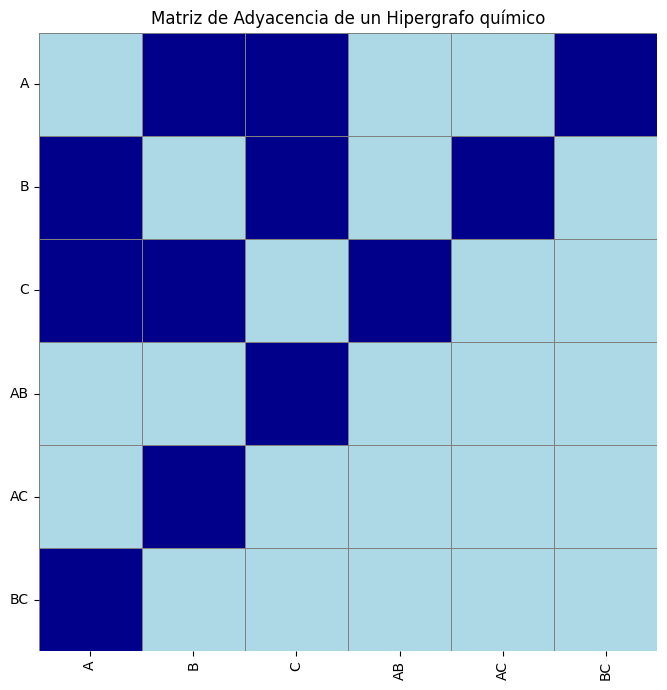

In [ ]:
import pandas as pd
import seaborn as sns
Hipernodos = [set_to_label(x) for x in P1]
adj_matrix = nx.to_pandas_adjacency(G1, dtype=int)
adj_matrix = adj_matrix.reindex(index=Hipernodos, columns=Hipernodos)

# Definir el mapa de colores: 0 (azul claro), 1 (azul marino)
cmap = sns.color_palette(['#ADD8E6', '#00008B'])  # lightblue, darkblue

plt.figure(figsize=(7, 7))
sns.heatmap(adj_matrix, cmap=cmap, linewidths=0.5, linecolor='gray', cbar=False, square=True)
plt.title("Matriz de Adyacencia de un Hipergrafo químico")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Visualización de bloques $M_{13}$ y $M_{22}$.

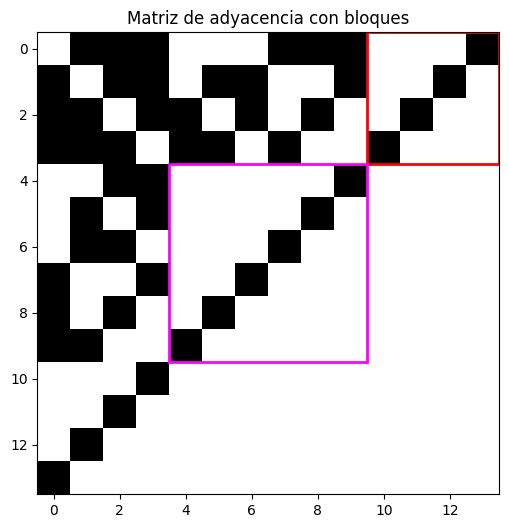

In [ ]:
import matplotlib.patches as patches

bloques = [
            (slice(0,4), slice(10,14), True),
            (slice(4,10), slice(4,10), True),
        ]

# Colores (puedes cambiar)
colores = [
    "red", "magenta"
]

fig, ax = plt.subplots(figsize=(6,6))

# Mostrar matriz
ax.imshow(A41, cmap="Greys")

# Dibujar bloques
for i, (fil, col, _) in enumerate(bloques):
    fila_inicio = fil.start
    fila_fin = fil.stop
    col_inicio = col.start
    col_fin = col.stop

    rect = patches.Rectangle(
        (col_inicio - 0.5, fila_inicio - 0.5),  # esquina
        col_fin - col_inicio,                  # ancho
        fila_fin - fila_inicio,                # alto
        linewidth=2,
        edgecolor=colores[i],
        facecolor='none'
    )

    ax.add_patch(rect)

# Ajustes visuales
ax.set_title(f"Matriz de adyacencia con bloques")

plt.show()

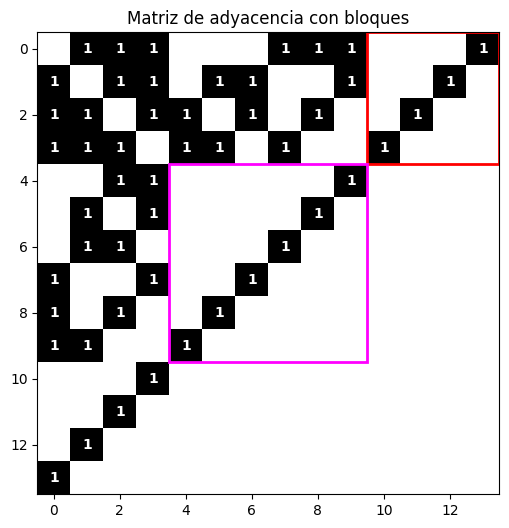

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np

fig, ax = plt.subplots(figsize=(6,6))

ax.imshow(A41, cmap="Greys")

# Escribir los valores de la matriz
for i in range(A41.shape[0]):
    for j in range(A41.shape[1]):
        ax.text(
            j, i, str(A41[i, j]),
            ha='center',
            va='center',
            color='white',
            fontsize=10,
            fontweight='bold'
        )

# Dibujar bloques
for i, (fil, col, _) in enumerate(bloques):
    fila_inicio = fil.start
    fila_fin = fil.stop
    col_inicio = col.start
    col_fin = col.stop

    rect = patches.Rectangle(
        (col_inicio - 0.5, fila_inicio - 0.5),
        col_fin - col_inicio,
        fila_fin - fila_inicio,
        linewidth=2,
        edgecolor=colores[i],
        facecolor='none'
    )
    ax.add_patch(rect)

ax.set_title("Matriz de adyacencia con bloques")

plt.show()

#Definición del grado del hipernodo

Dado un hipernodo $h_i$ identificado por un índice i.

Este índice corresponde a la fila/columna i de la matriz A.

El grado del hipernodo está definido por la relación:

$d(h_i)=2
^{n−i
−1}$

donde:

n = cardinalidad del hipernodo

i = índice del hipernodo (el mismo de la matriz A)


In [ ]:
import math
#Calcular n de la matriz de adyacencia

def compute_n_from_adjacency(A):
    N = A.shape[0]
    n = math.log2(N + 2)

    return int(n)

Función para calcular el grado de un Hiperonodo

In [ ]:
def grado_hipernodo(G,i):
    nodos = list(G.nodes())

      # Matriz de adyacencia coherente con nodos
    A = nx.to_numpy_array(G, nodelist=nodos)

     # Número de sustancias
    n = compute_n_from_adjacency(A)

    s = len(nodos[i])        # cardinalidad del hipernodo
    d = 2**(n - s) - 1       # grado según la definición

    return d


In [ ]:
#Prueba
i=28
d_hi = grado_hipernodo(G, i)
print(d_hi)

1


Clustering para proyección 1

In [ ]:
nx.clustering(G)

{'A': 0.23809523809523808,
 'B': 0.23809523809523808,
 'C': 0.23809523809523808,
 'D': 0.23809523809523808,
 'E': 0.23809523809523808,
 'AB': 0.2857142857142857,
 'AC': 0.2857142857142857,
 'AD': 0.2857142857142857,
 'AE': 0.2857142857142857,
 'BC': 0.2857142857142857,
 'BD': 0.2857142857142857,
 'BE': 0.2857142857142857,
 'CD': 0.2857142857142857,
 'CE': 0.2857142857142857,
 'DE': 0.2857142857142857,
 'ABC': 0.3333333333333333,
 'ABD': 0.3333333333333333,
 'ABE': 0.3333333333333333,
 'ACD': 0.3333333333333333,
 'ACE': 0.3333333333333333,
 'ADE': 0.3333333333333333,
 'BCD': 0.3333333333333333,
 'BCE': 0.3333333333333333,
 'BDE': 0.3333333333333333,
 'CDE': 0.3333333333333333,
 'ABCD': 0,
 'ABCE': 0,
 'ABDE': 0,
 'ACDE': 0,
 'BCDE': 0}

Hiperclustering

In [ ]:
import math
#Clustering P1
def clustering_hipernodo(A, G, i):
    """
    Calcula C_i evitando indeterminaciones cuando n = s o s = n - 1.
    """

    # Número de sustancias
    n = compute_n_from_adjacency(A)

    # cardinalidad del hipernodo
    nodos = list(G.nodes())
    s = len(nodos[i])

    k = n - s

    # Evitar indeterminaciones del denominador:
    # (2^k - 1)(2^k - 2) = 0 para k = 0 o k = 1
    if k <= 1:
        return float('nan')

    numerador = 3**k - 2**k + 1
    denominador = (2**k - 1) * (2**k - 2)

    return numerador / denominador


In [ ]:
C_3 = clustering_hipernodo(A4, G4, 2)
print(C_3)

0.09735988883742473


In [ ]:
#Hiperclustering
def clustering_hq(G, i):
    """
    Calcula el coeficiente de clustering HQ para el hipernodo i.
    """

    # Lista de nodos (orden fijo)
    nodos = list(G.nodes())

    # Matriz de adyacencia coherente con nodos
    A = nx.to_numpy_array(G, nodelist=nodos)

    # Validar índice
    if not (0 <= i < A.shape[0]):
        raise IndexError("El índice i está fuera del rango de la matriz.")

    # Cardinalidad del hipernodo
    s = len(nodos[i])

    # Número de sustancias
    n = compute_n_from_adjacency(A)

    if s > n:
        raise ValueError("Debe cumplirse s <= n.")

    # Calcular A^3
    A3 = A @ A @ A

    # Elemento diagonal (A^3)_{ii}
    A3_ii = A3[i, i]

    # Denominador HQ
    denom = 3**(n - s) - 2**(n - s + 1) + 1

    if denom <= 0:
        return 0.0

    return A3_ii / denom

In [ ]:
C_i = clustering_hq(G,i=16)
print(C_i)

1.0


Distribución de probabilidad de hipergrado

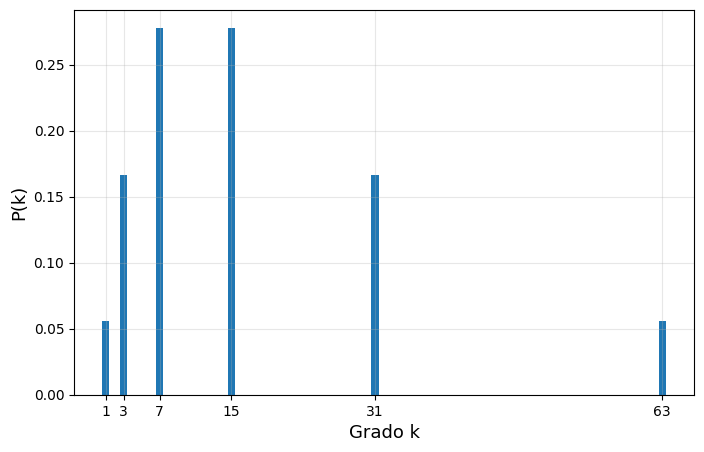

In [ ]:
grados = [d for _, d in G2.degree()]

# ------------------------------------------------
# Calcular distribución de probabilidad
# ------------------------------------------------

valores, conteos = np.unique(grados, return_counts=True)

P_k = conteos / np.sum(conteos)

# ------------------------------------------------
# Graficar
# ------------------------------------------------

plt.figure(figsize=(8,5))

plt.bar(valores, P_k)

plt.xlabel('Hipergrado k', fontsize=13)
plt.ylabel('P(k)', fontsize=13)

plt.xticks(valores)
plt.grid(alpha=0.3)

plt.show()

Cálculo de distancia y diámetro

In [ ]:
grafos = [G,G31,G41,G,G1, G2, G3, G4,G5]

for i, G in enumerate(grafos, start=1):
    if nx.is_connected(G):
        L = nx.average_shortest_path_length(G)
        print(f"G{i}: {L:.4f}")
    else:
        print(f"G{i}: No es conexo")

G1: 1.9655
G2: 1.8000
G3: 1.9231
G4: 1.9655
G5: 1.9836
G6: 1.9920
G7: 1.9960
G8: 1.9980
G9: 1.9990


In [ ]:
grafos = [G31,G41,G,G1, G2, G3, G4,G5]

for i, G in enumerate(grafos, start=1):
    if nx.is_connected(G):
        L = nx.diameter(G)
        print(f"G{i}: {L:.4f}")
    else:
        print(f"G{i}: No es conexo")

G1: 3.0000
G2: 3.0000
G3: 3.0000
G4: 3.0000
G5: 3.0000
G6: 3.0000
G7: 3.0000
G8: 3.0000


Pruebas con potencias de matrices de adyacencia

In [ ]:
A2 = np.matmul(A31,A31)
print(A2)

[[3 1 1 1 1 0]
 [1 3 1 1 0 1]
 [1 1 3 0 1 1]
 [1 1 0 1 0 0]
 [1 0 1 0 1 0]
 [0 1 1 0 0 1]]


In [ ]:
A3 = np.matmul(A2,A31)
print(A3)

[[2 5 5 1 1 3]
 [5 2 5 1 3 1]
 [5 5 2 3 1 1]
 [1 1 3 0 1 1]
 [1 3 1 1 0 1]
 [3 1 1 1 1 0]]


In [ ]:
print(A31+A2+A3)

[[5 7 7 2 2 4]
 [7 5 7 2 4 2]
 [7 7 5 4 2 2]
 [2 2 4 1 1 1]
 [2 4 2 1 1 1]
 [4 2 2 1 1 1]]


In [ ]:
A4 = np.matmul(A3,A31)
print(A4)

[[13  8  8  5  5  2]
 [ 8 13  8  5  2  5]
 [ 8  8 13  2  5  5]
 [ 5  5  2  3  1  1]
 [ 5  2  5  1  3  1]
 [ 2  5  5  1  1  3]]


Clustering de la proyección 1

In [ ]:
import networkx as nx

grafos = [G31, G41, G, G1, G2, G3, G4, G5]

for i, grafo in enumerate(grafos, start=1):
    if nx.is_connected(grafo):
        C = nx.clustering(grafo)
        C_prom = nx.average_clustering(grafo)

        print(f"\nG{i}")
        print(f"Clustering promedio: {C_prom:.4f}")
        print("Clustering por nodo:")
        for nodo, valor in C.items():
            print(f"  {nodo}: {valor:.4f}")
    else:
        print(f"G{i}: No es conexo")


G1
Clustering promedio: 0.1667
Clustering por nodo:
  A: 0.3333
  B: 0.3333
  C: 0.3333
  AB: 0.0000
  AC: 0.0000
  BC: 0.0000

G2
Clustering promedio: 0.2245
Clustering por nodo:
  A: 0.2857
  B: 0.2857
  C: 0.2857
  D: 0.2857
  AB: 0.3333
  AC: 0.3333
  AD: 0.3333
  BC: 0.3333
  BD: 0.3333
  CD: 0.3333
  ABC: 0.0000
  ABD: 0.0000
  ACD: 0.0000
  BCD: 0.0000

G3
Clustering promedio: 0.1955
Clustering por nodo:
  A: 0.0716
  B: 0.0716
  C: 0.0716
  D: 0.0716
  E: 0.0716
  F: 0.0716
  G: 0.0716
  H: 0.0716
  I: 0.0716
  J: 0.0716
  AB: 0.0934
  AC: 0.0934
  AD: 0.0934
  AE: 0.0934
  AF: 0.0934
  AG: 0.0934
  AH: 0.0934
  AI: 0.0934
  AJ: 0.0934
  BC: 0.0934
  BD: 0.0934
  BE: 0.0934
  BF: 0.0934
  BG: 0.0934
  BH: 0.0934
  BI: 0.0934
  BJ: 0.0934
  CD: 0.0934
  CE: 0.0934
  CF: 0.0934
  CG: 0.0934
  CH: 0.0934
  CI: 0.0934
  CJ: 0.0934
  DE: 0.0934
  DF: 0.0934
  DG: 0.0934
  DH: 0.0934
  DI: 0.0934
  DJ: 0.0934
  EF: 0.0934
  EG: 0.0934
  EH: 0.0934
  EI: 0.0934
  EJ: 0.0934
  FG: 0.0